# EJEMPLO 2
## Transferencia de Aprendizaje

In [1]:
import tensorflow as tf
from tensorflow import keras
print("Versión TF", tf.__version__)

Versión TF 2.21.0


**Carga del Dataset**

Carga un dataset de tomates saludables y dañados que ha sido redimensionado de imágenes 800x600 a 224x224. La siguiente es la referencia del dataset original:

> Mishra, S., & Sharma, S. (2026). INDTomatoMSTD: A Multi-Scale Tomato Disease Dataset for Tiny and Large Lesion Detection Using Deep Transfer Learning. INDTomatoMSTD: A Multi-Scale Tomato Disease Dataset for Tiny and Large Lesion Detection Using Deep Transfer Learning. IEEE Dataport. doi:10.21227/2194-m629

Recuerde descargar el dataset (https://drive.google.com/drive/folders/1tgWYkGgEp3k1glY6ZrhXql8EpO3zKFxL?usp=drive_link) y subirlo a su carpeta local de GoogleDrive.

Puede usar el siguiente prompt para cargar el dataset y partirlo en conjuntos de entrenamiento, validación y prueba:

> Necesito que cargues el dataset que tengo en mi carpeta de googledrive en la ruta "cursos\Taller_Deeplearning_Villavicencio\dataset_resized". El dataset tiene dos clases: Healthy y Rejected. Las imágenes de cada clase están en subcarpetas del mismo nombre. Carga inicialmente los dos dataset, uno por cada clase, crea un vector de etiquetas, y luego realiza una partición de estos dataset de la siguiente forma: entrenamiento 80%, validación 10% y prueba 10% de los datos.

In [2]:
import tensorflow as tf
from tensorflow import keras
from google.colab import drive
import os

# 1. Montar Google Drive
drive.mount('/content/drive')

# Ruta del dataset en Google Drive
dataset_path = '/content/drive/MyDrive/cursos/Taller_Deeplearning_Villavicencio/dataset_resized_small'

IMG_SIZE = 224
BATCH_SIZE = 8
SEED = 123

if os.path.exists(dataset_path):
    # 2. Carga inicial de todo el dataset (reconoce subcarpetas como clases y crea el vector de etiquetas)
    full_ds = keras.utils.image_dataset_from_directory(
        dataset_path,
        shuffle=True,
        seed=SEED,
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE
    )

    class_names = full_ds.class_names
    print("\nClases detectadas:", class_names)

    num_batches = len(full_ds)
    print(f"Total de lotes (batches) cargados: {num_batches}")

    # 3. Calcular los tamaños para la partición: 80% / 10% / 10%
    train_size = int(0.8 * num_batches)
    val_size = int(0.1 * num_batches)
    test_size = num_batches - train_size - val_size

    # Fraccionar usando la API tf.data
    train_ds = full_ds.take(train_size)
    remaining_ds = full_ds.skip(train_size)
    val_ds = remaining_ds.take(val_size)
    test_ds = remaining_ds.skip(val_size)

    print(f"Batches para entrenamiento (80%): {len(train_ds)} (~{len(train_ds) * BATCH_SIZE} imágenes)")
    print(f"Batches para validación (10%): {len(val_ds)} (~{len(val_ds) * BATCH_SIZE} imágenes)")
    print(f"Batches para prueba (10%): {len(test_ds)} (~{len(test_ds) * BATCH_SIZE} imágenes)")

    # Optimización de rendimiento con prefetch
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)
else:
    print(f"La ruta '{dataset_path}' no es accesible. Por favor verifica que la carpeta exista en tu Google Drive.")

Mounted at /content/drive
Found 200 files belonging to 2 classes.

Clases detectadas: ['Healthy', 'Rejected']
Total de lotes (batches) cargados: 25
Batches para entrenamiento (80%): 20 (~160 imágenes)
Batches para validación (10%): 2 (~16 imágenes)
Batches para prueba (10%): 3 (~24 imágenes)


**Crea el modelo basado en MobileNetV3 Small**

Para ello, carga únicamente las primeras capas asociadas a la extracción de características y elimina las capas asociadas a la clasificación. Estas se reemplazan por nuevas capas para hacer la clasificación en dos categorías: Healthy y Rejected.

Puedes usar el siguiente prompt:

> Crea un modelo basado en MobuleNetV3 Small que permita entrenar las capas de clasificación, es decir, cambiar la cabeza del modelo por uno que permita clasificar los dos patrones del dataset. Muestra al final un resumen del número de parámetros del modelo.

In [3]:
IMG_SIZE = 224

# Crea un modelo basado en MobileNetV3 Small cambiando la cabeza del modelo
base_model = tf.keras.applications.MobileNetV3Small(
    input_shape=(IMG_SIZE,IMG_SIZE,3),
    include_top=False,
    weights="imagenet"
)

num_classes = len(class_names)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE,IMG_SIZE,3))
x = tf.keras.applications.mobilenet_v3.preprocess_input(inputs)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.summary()


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         1,154 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 940,274 (3.59 MB)

 Trainable params: 1,154 (4.51 KB)

 Non-trainable params: 939,120 (3.58 MB)

**Entrenamiento de las capas de clasificación**

Puedes usar el siguiente prompt:

> Compila y entrena el modelo usando el dataset de entrenamiento y validación usando el algoritmo Adam. Añade las estrategias para evitar overfitting de EarlyStopping y ModelCheckpoint. Grafica las curvas de evolución de accuracy y loss con las épocas para los conjuntos de entrenamiento y validación

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 532ms/step - accuracy: 0.5491 - loss: 0.7875
Epoch 1: val_loss improved from None to 0.62031, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 964ms/step - accuracy: 0.6000 - loss: 0.7429 - val_accuracy: 0.7500 - val_loss: 0.6203
Epoch 2/10
17/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6733 - loss: 0.6062
Epoch 2: val_loss improved from 0.62031 to 0.40316, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.7000 - loss: 0.5622 - val_accuracy: 0.7500 - val_loss: 0.4032
Epoch 3/10
18/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6981 - loss: 0.5475
Epoch 3: val_loss improved from 0.40316 to 0.29180, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.7375 - loss: 0.5108 - val_accuracy: 1.0000 - val

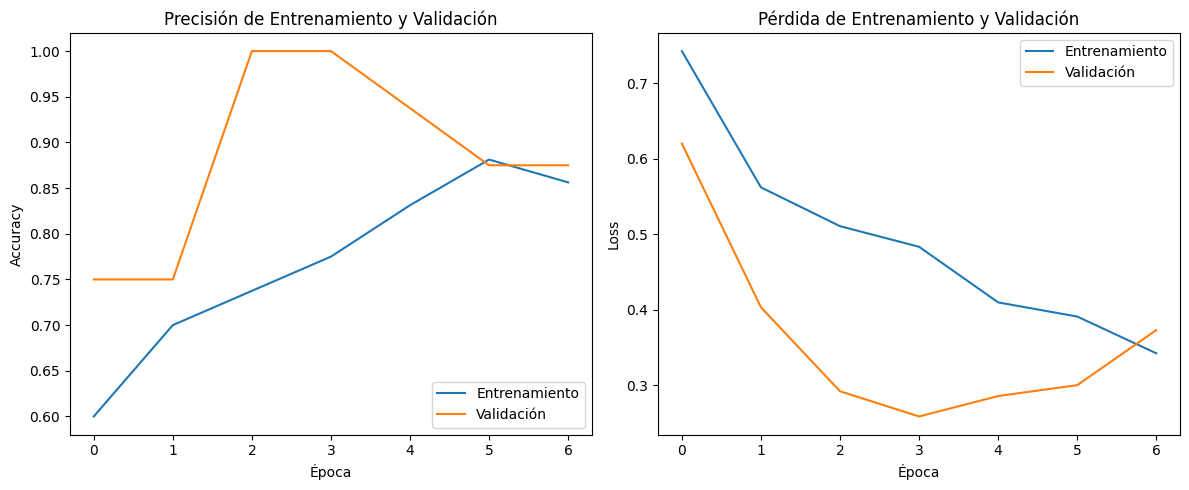

In [4]:
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Compilar el modelo
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Configurar callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath='best_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# Entrenar el modelo con los callbacks
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, model_checkpoint]
)

# Graficar el histórico de Accuracy y Loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entrenamiento')
plt.plot(epochs_range, val_acc, label='Validación')
plt.legend(loc='lower right')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy')

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entrenamiento')
plt.plot(epochs_range, val_loss, label='Validación')
plt.legend(loc='upper right')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

**Guarda el modelo**

In [5]:
model.save("clasificador_tomates_v1.keras")

**Fine-tuning**

Realiza un proceso de reentrenamiento por Fine-Tunning donde las últimas capas del modelo (no solamente las capas de clasificación) son ajustadas. Este proceso mejora la calidad del modelo.

Epoch 1/10
17/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5693 - loss: 1.1523
Epoch 1: val_loss did not improve from 0.25840
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 251ms/step - accuracy: 0.5000 - loss: 1.3459 - val_accuracy: 0.9375 - val_loss: 0.2880
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5363 - loss: 1.0729
Epoch 2: val_loss did not improve from 0.25840
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5437 - loss: 1.1461 - val_accuracy: 0.8750 - val_loss: 0.3248
Epoch 3/10
18/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5211 - loss: 1.0700
Epoch 3: val_loss did not improve from 0.25840
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5625 - loss: 0.9871 - val_accuracy: 0.8750 - val_loss: 0.2759
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


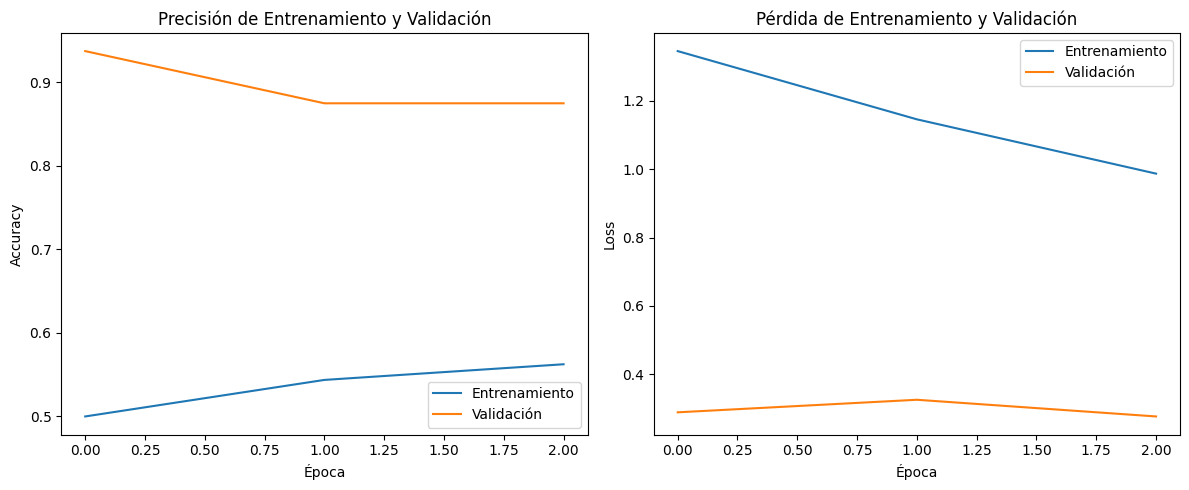

In [6]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenar el modelo con los callbacks
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, model_checkpoint]
)

# Graficar el histórico de Accuracy y Loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entrenamiento')
plt.plot(epochs_range, val_acc, label='Validación')
plt.legend(loc='lower right')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy')

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entrenamiento')
plt.plot(epochs_range, val_loss, label='Validación')
plt.legend(loc='upper right')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

**Exporta el modelo a un formato TFLite**

In [7]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("clasificador_tomates_v1.tflite", "wb") as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmp1zgqd30h'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_175')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140463287960016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416127184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416128528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416128720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1404604161

**Exporta el modelo cuantizado en formato INT8 a TFLite**

In [8]:
import tensorflow as tf
import numpy as np

# 1. Definir un generador de datos representativos utilizando el dataset existente
def representative_data_gen():
    # Usamos un lote pequeño del dataset para la calibración
    for input_value, _ in val_ds.take(20):
        # Convertimos las imágenes a tipo float32
        yield [tf.cast(input_value, tf.float32)]

# 2. Configurar el convertidor de TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Habilitar optimizaciones
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Configurar el generador de datos representativos obligatorio para INT8
converter.representative_dataset = representative_data_gen

# Restringir las operaciones para asegurar compatibilidad total con TFLite Micro
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

# Configurar entrada y salida del modelo de inferencia en INT8
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# 3. Convertir el modelo
tflite_quant_model = converter.convert()

# 4. Guardar el archivo cuantizado
tflite_model_path = "clasificador_tomates_quant_int8.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_quant_model)

print(f"Modelo cuantizado en INT8 exportado exitosamente a: {tflite_model_path}")

Saved artifact at '/tmp/tmpn0kgqvd3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_175')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140463287960016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416127184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416128528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416128720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416130448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140460416129488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1404604161

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Modelo cuantizado en INT8 exportado exitosamente a: clasificador_tomates_quant_int8.tflite


In [9]:
# Script en Python puro para emular el comando xxd y exportar el modelo a C
# Comando original: xxd -i modelo.tflite > modelo.h

def export_tflite_to_c(input_filename, output_filename):
    with open(input_filename, "rb") as f:
        bytes_data = f.read()
    var_name = input_filename.replace(".", "_")
    with open(output_filename, "w") as f:
        f.write(f"// Arreglo de bytes del modelo generado por Python\n")
        f.write(f"const unsigned char {var_name}[] = {{\n    ")
        for i, byte in enumerate(bytes_data):
            f.write(f"0x{byte:02x}")
            if i < len(bytes_data) - 1:
                f.write(", ")
            if (i + 1) % 12 == 0:
                f.write("\n    ")
        f.write("\n};\n\n")
        f.write(f"const unsigned int {var_name}_len = {len(bytes_data)};\n")

    print(f"¡Archivo '{output_filename}' creado con éxito en Python!")

In [10]:
export_tflite_to_c('clasificador_tomates_v1.tflite', 'clasificador_tomates_v1.h')

¡Archivo 'clasificador_tomates_v1.h' creado con éxito en Python!
